# Ensamble de Modelos: Teoría Completa
## Bagging, Random Forest, Boosting (AdaBoost, Gradient Boosting, XGBoost)

**Machine Learning 1 — FIUNA**

**Docente:** Diego Stalder | **Práctica:** Carlos Benítez

---

## Descripción

Los **métodos de ensamble** combinan múltiples modelos débiles para construir un modelo fuerte. Son la base de los algoritmos más exitosos en competencias de Machine Learning (XGBoost, LightGBM, CatBoost) y en aplicaciones industriales.

**Idea central:** un modelo solo puede equivocarse de ciertas formas; combinando modelos con errores decorrelacionados, los errores individuales se cancelan.

## Estructura

1. **Fundamento teórico** — sesgo, varianza y descomposición del error
2. **Bagging** — Bootstrap Aggregating, reducción de varianza
3. **Random Forest** — bagging + selección aleatoria de características
4. **Boosting** — construcción secuencial, reducción de sesgo
5. **AdaBoost** — boosting adaptativo con pesos
6. **Gradient Boosting** — boosting como descenso de gradiente funcional
7. **XGBoost** — gradient boosting regularizado y escalable
8. **Comparación y guía práctica**
9. **Referencias bibliográficas**

## Referencias principales

- **Breiman, L. (1996).** *Bagging Predictors*. Machine Learning, 24(2), 123-140.
- **Breiman, L. (2001).** *Random Forests*. Machine Learning, 45(1), 5-32.
- **Freund, Y., & Schapire, R. E. (1997).** *A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting*. JCSS, 55(1), 119-139.
- **Friedman, J. H. (2001).** *Greedy Function Approximation: A Gradient Boosting Machine*. Annals of Statistics, 29(5), 1189-1232.
- **Chen, T., & Guestrin, C. (2016).** *XGBoost: A Scalable Tree Boosting System*. KDD 2016.
- **Hastie, T., Tibshirani, R., & Friedman, J. (2009).** *The Elements of Statistical Learning*. Cap. 15-17.

## 0. Importaciones y Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sympy as sp
from sympy import symbols, log, diff, simplify, solve, Rational, exp, init_printing, Symbol, sqrt

from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split

init_printing(use_latex='mathjax')

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 11,
    'axes.grid': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 100
})
sns.set_palette('husl')
np.random.seed(42)

print("="*80)
print("🎯 ENSAMBLE DE MODELOS — Clase Teórica Completa")
print("="*80)
print(f"SymPy versión: {sp.__version__}")

🎯 ENSAMBLE DE MODELOS — Clase Teórica Completa
SymPy versión: 1.13.1


---
# Parte 1: Fundamento Teórico

## 1.1 ¿Por qué funcionan los ensambles?

Supongamos que tenemos $M$ modelos base con errores $\epsilon_1, \ldots, \epsilon_M$ y los combinamos por **promedio** (para regresión):

$$\hat{f}_{\text{ens}}(\mathbf{x}) = \frac{1}{M} \sum_{m=1}^{M} \hat{f}_m(\mathbf{x})$$

El error del ensamble respecto al valor verdadero es:

$$\epsilon_{\text{ens}} = \frac{1}{M} \sum_{m=1}^{M} \epsilon_m$$

El **error cuadrático medio esperado** es:

$$\mathbb{E}[\epsilon_{\text{ens}}^2] = \frac{1}{M^2} \mathbb{E}\left[\left(\sum_{m=1}^{M} \epsilon_m\right)^2\right]$$

Expandiendo:

$$\mathbb{E}[\epsilon_{\text{ens}}^2] = \frac{1}{M^2} \left( \sum_{m=1}^{M} \mathbb{E}[\epsilon_m^2] + \sum_{m \neq m'} \mathbb{E}[\epsilon_m \epsilon_{m'}] \right)$$

Definimos:
- $\sigma^2 = \mathbb{E}[\epsilon_m^2]$: varianza del error individual
- $\rho = \frac{\mathbb{E}[\epsilon_m \epsilon_{m'}]}{\sigma^2}$: **correlación** entre errores de modelos distintos

Entonces:

$$\boxed{\mathbb{E}[\epsilon_{\text{ens}}^2] = \rho \sigma^2 + \frac{1-\rho}{M} \sigma^2}$$

**Interpretación:**
- Si $\rho = 0$ (errores independientes): $\mathbb{E}[\epsilon^2] \to 0$ cuando $M \to \infty$
- Si $\rho = 1$ (errores idénticos): $\mathbb{E}[\epsilon^2] = \sigma^2$ (sin mejora)
- **Cuanto menor la correlación, más efectivo el ensamble**

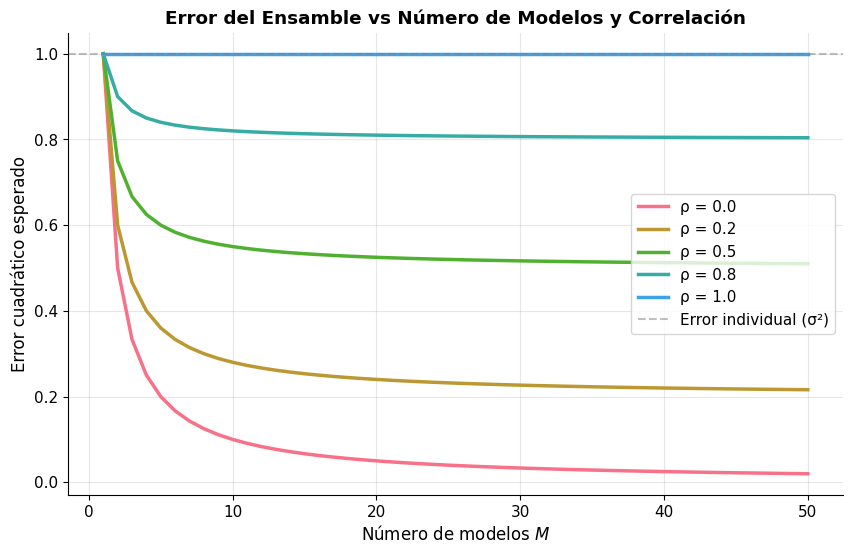

📊 Lecciones:
   - ρ=0 (independientes): el error tiende a 0
   - ρ=1 (idénticos): no hay mejora
   - ρ moderada: el error converge a un valor positivo
   - Para M grande, el término (1-ρ)/M se vuelve despreciable


In [2]:
# Visualización del error del ensamble vs número de modelos y correlación
M_vals = np.arange(1, 51)
sigma2 = 1.0
rhos = [0.0, 0.2, 0.5, 0.8, 1.0]

plt.figure(figsize=(10, 6))
for rho in rhos:
    error = rho * sigma2 + (1 - rho) / M_vals * sigma2
    plt.plot(M_vals, error, linewidth=2.5, label=f'ρ = {rho}')

plt.axhline(y=sigma2, color='gray', linestyle='--', alpha=0.5, label='Error individual (σ²)')
plt.xlabel('Número de modelos $M$', fontsize=12)
plt.ylabel('Error cuadrático esperado', fontsize=12)
plt.title('Error del Ensamble vs Número de Modelos y Correlación', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("📊 Lecciones:")
print("   - ρ=0 (independientes): el error tiende a 0")
print("   - ρ=1 (idénticos): no hay mejora")
print("   - ρ moderada: el error converge a un valor positivo")
print("   - Para M grande, el término (1-ρ)/M se vuelve despreciable")

## 1.2 Descomposición Sesgo-Varianza

El error esperado de cualquier modelo se descompone en:

$$\boxed{\mathbb{E}[(y - \hat{f}(\mathbf{x}))^2] = \underbrace{\text{Bias}^2[\hat{f}]}_{\text{sesgo}^2} + \underbrace{\text{Var}[\hat{f}]}_{\text{varianza}} + \underbrace{\sigma_\epsilon^2}_{\text{ruido irreducible}}}$$

donde:
- **Sesgo:** diferencia entre la predicción promedio y el valor verdadero. Mide lo "equivocado" que está el modelo en promedio.
- **Varianza:** variabilidad de la predicción ante cambios en los datos de entrenamiento. Mide la **sensibilidad**.
- **Ruido:** error irreducible del propio problema.

**Diferencia clave entre Bagging y Boosting:**

| Técnica | Método | Componente que reduce |
|---------|--------|----------------------|
| **Bagging** | Paralelo (bootstrap + promedio) | **Varianza** |
| **Boosting** | Secuencial (corrección de errores) | **Sesgo** |

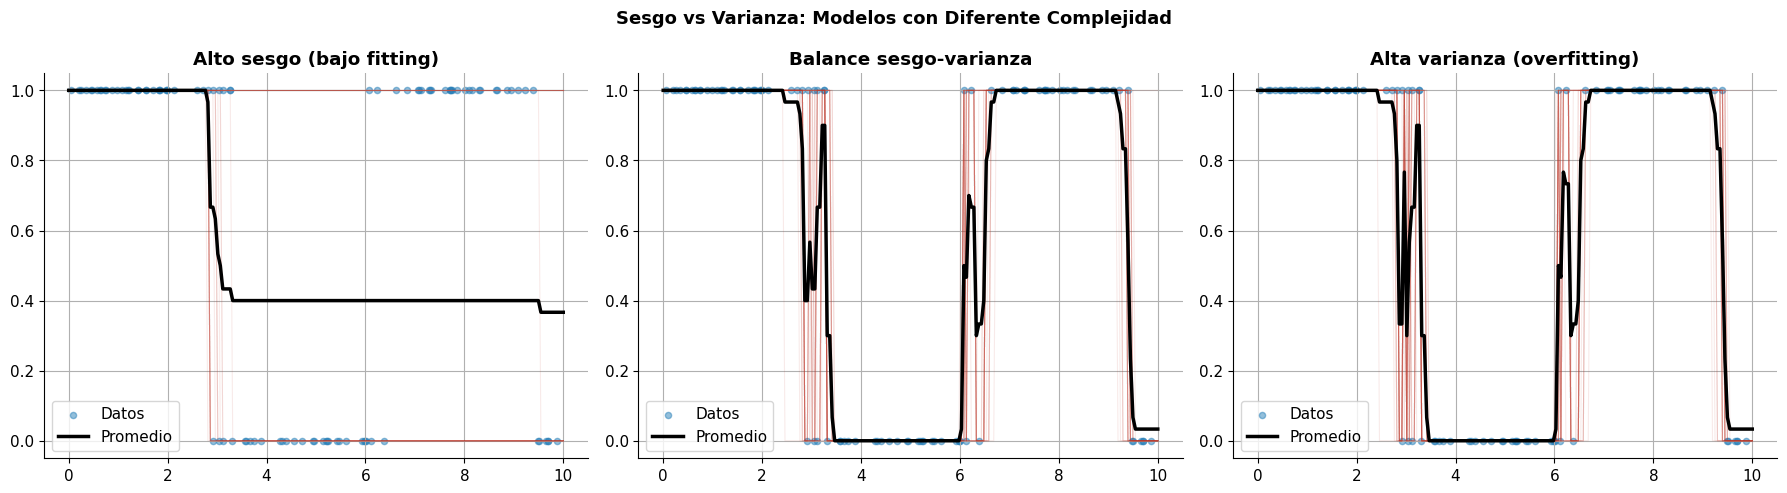

📊 Observaciones:
   - Árboles muy simples (depth=1): alta varianza baja pero alto sesgo
   - Árboles complejos (sin límite): bajo sesgo pero ALTA VARIANZA
   - El ensamble (promedio) reduce la varianza manteniendo bajo sesgo


In [3]:
# Ilustración de sesgo-varianza con modelos simples vs complejos
np.random.seed(42)
X_bv = np.random.uniform(0, 10, 100).reshape(-1, 1)
y_bv = np.sin(X_bv).ravel() + np.random.normal(0, 0.3, 100)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
X_plot = np.linspace(0, 10, 200).reshape(-1, 1)

for ax, (depth, title) in zip(axes, [(1, 'Alto sesgo (bajo fitting)'),
                                     (5, 'Balance sesgo-varianza'),
                                     (None, 'Alta varianza (overfitting)')]):
    # Entrenar varios árboles con diferentes subconjuntos
    predictions = []
    for seed in range(30):
        np.random.seed(seed)
        idx = np.random.choice(len(X_bv), len(X_bv), replace=True)
        tree = DecisionTreeClassifier(max_depth=depth, random_state=seed)
        tree.fit(X_bv[idx], (y_bv[idx] > 0).astype(int))
        predictions.append(tree.predict(X_plot))
    
    ax.scatter(X_bv, (y_bv > 0).astype(int), c='#2980B9', s=20, alpha=0.5, label='Datos')
    for p in predictions:
        ax.plot(X_plot, p, color='#C0392B', alpha=0.1, linewidth=0.8)
    ax.plot(X_plot, np.mean(predictions, axis=0), color='black', linewidth=2.5, label='Promedio')
    ax.set_title(title, fontweight='bold')
    ax.legend()

plt.suptitle('Sesgo vs Varianza: Modelos con Diferente Complejidad', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("📊 Observaciones:")
print("   - Árboles muy simples (depth=1): alta varianza baja pero alto sesgo")
print("   - Árboles complejos (sin límite): bajo sesgo pero ALTA VARIANZA")
print("   - El ensamble (promedio) reduce la varianza manteniendo bajo sesgo")

---
# Parte 2: Bagging (Bootstrap Aggregating)

## 2.1 Idea principal

**Bagging** (Breiman, 1996) combina dos ideas:

1. **Bootstrap:** generar $M$ muestras con reemplazo de tamaño $n$ cada una
2. **Aggregating:** entrenar $M$ modelos (uno por muestra) y **promediar** sus predicciones

## 2.2 Formalización

Para $m = 1, \ldots, M$:
1. Generar muestra bootstrap $D_m$ de $D$ (muestreo con reemplazo)
2. Entrenar modelo $\hat{f}_m$ sobre $D_m$

**Predicción del ensamble:**

$$\boxed{\hat{f}_{\text{bag}}(\mathbf{x}) = \frac{1}{M} \sum_{m=1}^{M} \hat{f}_m(\mathbf{x}) \quad \text{(regresión)}}$$

$$\boxed{\hat{f}_{\text{bag}}(\mathbf{x}) = \text{mode}\{\hat{f}_1(\mathbf{x}), \ldots, \hat{f}_M(\mathbf{x})\} \quad \text{(clasificación)}}$$

## 2.3 ¿Por qué funciona?

**Para árboles de decisión:** un árbol entrenado con un subconjunto bootstrap es **diferente** al entrenado con otro. Sus errores son **parcialmente independientes**.

Aplicando la fórmula de descomposición del error:

$$\text{Var}[\hat{f}_{\text{bag}}] = \rho \sigma^2 + \frac{1-\rho}{M} \sigma^2$$

**Bagging reduce la varianza** del modelo sin cambiar significativamente el sesgo.

## 2.4 Propiedades del bootstrap

**Proporción de muestras únicas en una muestra bootstrap:**

Cada muestra tiene probabilidad $(1 - 1/n)$ de **no** ser elegida en cada extracción. Como hay $n$ extracciones:

$$P(\text{no elegida}) = (1 - 1/n)^n \approx e^{-1} \approx 0.368$$

Por lo tanto:

$$\boxed{\text{Proporción de muestras únicas en bootstrap} \approx 1 - e^{-1} \approx 63.2\%}$$

El 36.8% restante son **out-of-bag (OOB)** y pueden usarse para validación interna.

📊 VERIFICACIÓN EMPÍRICA: PROPORCIÓN DE MUESTRAS ÚNICAS EN BOOTSTRAP

n          | Proporción única (empírica) | 1 - e⁻¹ (teórica)   
------------------------------------------------------------
10         | 0.6500                    | 0.6321              
50         | 0.6274                    | 0.6321              
100        | 0.6356                    | 0.6321              
500        | 0.6316                    | 0.6321              
1000       | 0.6323                    | 0.6321              
5000       | 0.6326                    | 0.6321              


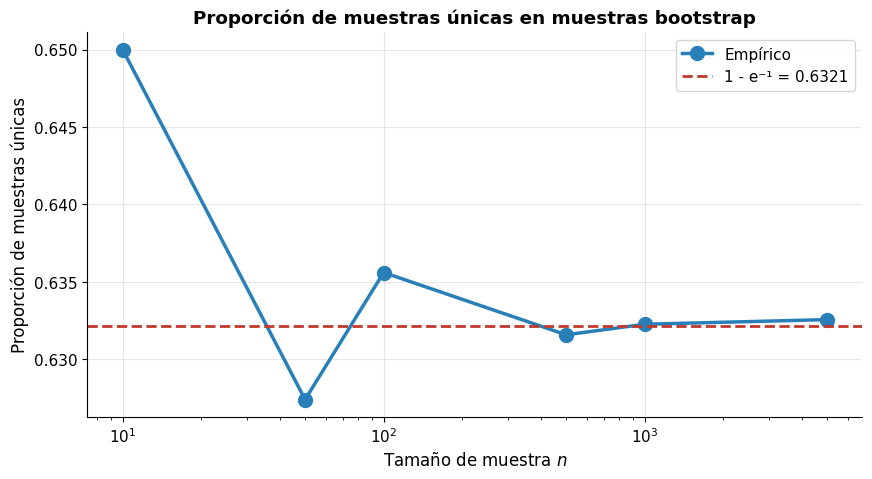

In [4]:
# Verificación empírica del 63.2% de muestras únicas
np.random.seed(42)

sizes = [10, 50, 100, 500, 1000, 5000]
unique_proportions = []

for n in sizes:
    props = []
    for _ in range(100):
        bootstrap = np.random.choice(n, size=n, replace=True)
        props.append(len(np.unique(bootstrap)) / n)
    unique_proportions.append(np.mean(props))

print("="*80)
print("📊 VERIFICACIÓN EMPÍRICA: PROPORCIÓN DE MUESTRAS ÚNICAS EN BOOTSTRAP")
print("="*80)
print(f"\n{'n':<10} | {'Proporción única (empírica)':<25} | {'1 - e⁻¹ (teórica)':<20}")
print("-" * 60)
for n, prop in zip(sizes, unique_proportions):
    print(f"{n:<10} | {prop:<25.4f} | {1-np.exp(-1):<20.4f}")

# Visualización
plt.figure(figsize=(10, 5))
plt.semilogx(sizes, unique_proportions, 'o-', color='#2980B9', linewidth=2.5, markersize=10, label='Empírico')
plt.axhline(y=1-np.exp(-1), color='#C0392B', linestyle='--', linewidth=2, label=f'1 - e⁻¹ = {1-np.exp(-1):.4f}')
plt.xlabel('Tamaño de muestra $n$', fontsize=12)
plt.ylabel('Proporción de muestras únicas', fontsize=12)
plt.title('Proporción de muestras únicas en muestras bootstrap', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 2.5 Ejemplo numérico: reducción de varianza

**Escenario:** un modelo base tiene varianza $\sigma^2 = 0.25$. ¿Cuánto reduce el bagging con diferentes correlaciones y números de modelos?

In [5]:
# Ejemplo numérico de reducción de varianza
sigma2 = 0.25
print("="*80)
print(f"📊 EJEMPLO: REDUCCIÓN DE VARIANZA CON BAGGING (σ² = {sigma2})")
print("="*80)

print(f"\n{'M':<5} | {'ρ=0':<10} | {'ρ=0.2':<10} | {'ρ=0.5':<10} | {'ρ=0.8':<10}")
print("-" * 50)

for M in [1, 5, 10, 50, 100, 500]:
    row = f"{M:<5} |"
    for rho in [0.0, 0.2, 0.5, 0.8]:
        var = rho * sigma2 + (1 - rho) / M * sigma2
        row += f" {var:<10.4f}|"
    print(row)

print(f"\n💡 Lecciones:")
print(f"   - Con ρ=0 y M→∞, la varianza tiende a 0")
print(f"   - Con ρ=0.8 y M→∞, la varianza se estabiliza en ρ·σ² = {0.8*sigma2:.4f}")
print(f"   - Bagging no puede eliminar la varianza debida a la correlación")
print(f"   - Random Forest reduce ρ al aleatorizar features (sección 3)")

📊 EJEMPLO: REDUCCIÓN DE VARIANZA CON BAGGING (σ² = 0.25)

M     | ρ=0        | ρ=0.2      | ρ=0.5      | ρ=0.8     
--------------------------------------------------
1     | 0.2500    | 0.2500    | 0.2500    | 0.2500    |
5     | 0.0500    | 0.0900    | 0.1500    | 0.2100    |
10    | 0.0250    | 0.0700    | 0.1375    | 0.2050    |
50    | 0.0050    | 0.0540    | 0.1275    | 0.2010    |
100   | 0.0025    | 0.0520    | 0.1263    | 0.2005    |
500   | 0.0005    | 0.0504    | 0.1253    | 0.2001    |

💡 Lecciones:
   - Con ρ=0 y M→∞, la varianza tiende a 0
   - Con ρ=0.8 y M→∞, la varianza se estabiliza en ρ·σ² = 0.2000
   - Bagging no puede eliminar la varianza debida a la correlación
   - Random Forest reduce ρ al aleatorizar features (sección 3)


---
# Parte 3: Random Forest

## 3.1 Del Bagging al Random Forest

**Problema del bagging con árboles:** si hay una característica muy predictiva, casi todos los árboles la usan en la raíz → los árboles son **similares** → **alta correlación** $\rho$ → poca mejora del ensamble.

**Solución de Random Forest (Breiman, 2001):** en **cada división**, considerar solo un **subconjunto aleatorio de características**.

## 3.2 Algoritmo

Para construir cada árbol $m = 1, \ldots, M$:
1. Generar muestra bootstrap $D_m$
2. Para cada nodo del árbol:
   - Seleccionar aleatoriamente $m_{\text{try}}$ características de las $d$ disponibles
   - Buscar la mejor división **solo entre las $m_{\text{try}}$ seleccionadas**
3. Crecer el árbol sin poda (o con poda mínima)

**Hiperparámetro clave:** $m_{\text{try}}$ (o `max_features` en sklearn)

| Tarea | Valor típico de $m_{\text{try}}$ |
|-------|----------------------------------|
| **Clasificación** | $\sqrt{d}$ |
| **Regresión** | $d/3$ |

## 3.3 Efecto de $m_{\text{try}}$ en la correlación

- $m_{\text{try}} = d$ (todas las features): **Bagging puro**, $\rho$ alta, poca mejora
- $m_{\text{try}} = 1$: máxima decorrelación, pero árboles individuales muy débiles
- $m_{\text{try}} = \sqrt{d}$: **balance óptimo** entre decorrelación y fuerza individual

## 3.4 Fórmula de la varianza del Random Forest

$$\text{Var}[\hat{f}_{\text{RF}}] = \rho \sigma^2 + \frac{1-\rho}{M} \sigma^2$$

Pero ahora $\rho$ es **menor** que en bagging porque los árboles usan diferentes subconjuntos de features. La reducción adicional de $\rho$ compensa el aumento de $\sigma^2$ (árboles individualmente más débiles).

## 3.5 Out-of-Bag (OOB) Error

Cada muestra bootstrap deja fuera $\approx 36.8\%$ de los datos. Para cada observación $i$, podemos predecir usando **solo los árboles donde $i$ fue OOB**:

$$\hat{y}_i^{\text{OOB}} = \frac{1}{|\{m : i \in \text{OOB}_m\}|} \sum_{m : i \in \text{OOB}_m} \hat{f}_m(\mathbf{x}_i)$$

El **error OOB** es una estimación insesgada del error de test **sin necesidad de split**.

In [6]:
# Visualización: Bagging vs Random Forest (concepto)
print("="*80)
print("📊 BAGGING VS RANDOM FOREST: DIFERENCIA CLAVE")
print("="*80)

print("\n📌 Bagging con árboles:")
print("   - Cada árbol usa TODAS las features")
print("   - Si una feature es muy predictiva, todos los árboles la usan")
print("   - ρ (correlación entre árboles) ALTA")
print("   - Reducción de varianza LIMITADA")

print("\n📌 Random Forest:")
print("   - Cada nodo usa un SUBCONJUNTO aleatorio de features")
print("   - Los árboles se ven OBLIGADOS a usar features diferentes")
print("   - ρ (correlación entre árboles) BAJA")
print("   - Reducción de varianza MAYOR")

print("\n💡 Intuición: Random Forest es 'bagging + decorrelación'")
print("   Los árboles individuales son un poco más débiles (mayor sesgo),")
print("   pero su baja correlación permite una mayor reducción de varianza.")

📊 BAGGING VS RANDOM FOREST: DIFERENCIA CLAVE

📌 Bagging con árboles:
   - Cada árbol usa TODAS las features
   - Si una feature es muy predictiva, todos los árboles la usan
   - ρ (correlación entre árboles) ALTA
   - Reducción de varianza LIMITADA

📌 Random Forest:
   - Cada nodo usa un SUBCONJUNTO aleatorio de features
   - Los árboles se ven OBLIGADOS a usar features diferentes
   - ρ (correlación entre árboles) BAJA
   - Reducción de varianza MAYOR

💡 Intuición: Random Forest es 'bagging + decorrelación'
   Los árboles individuales son un poco más débiles (mayor sesgo),
   pero su baja correlación permite una mayor reducción de varianza.


---
# Parte 4: Boosting

## 4.1 Idea principal

**Boosting** construye modelos **secuencialmente**, donde cada modelo nuevo intenta corregir los errores del anterior.

**Diferencia con bagging:**
- Bagging: modelos **independientes** en paralelo → reduce **varianza**
- Boosting: modelos **dependientes** en secuencia → reduce **sesgo**

## 4.2 Formulación general

El ensamble se construye como:

$$\boxed{F_M(\mathbf{x}) = \sum_{m=1}^{M} \alpha_m \cdot h_m(\mathbf{x})}$$

donde:
- $h_m$: modelo débil en la iteración $m$
- $\alpha_m$: peso del modelo $m$ (importancia)
- $F_M$: predicción final del ensamble

## 4.3 AdaBoost: Adaptive Boosting

**Freund & Schapire (1997).** Algoritmo específico para clasificación binaria.

**Idea:** re-ponderar las muestras. Las muestras mal clasificadas ganan peso en la siguiente iteración.

### Algoritmo

**Inicialización:** $w_i^{(1)} = 1/n$ para $i = 1, \ldots, n$

**Para** $m = 1, \ldots, M$:
1. Entrenar clasificador débil $h_m$ con pesos $w^{(m)}$
2. Calcular el error ponderado:
   $$\epsilon_m = \sum_{i=1}^{n} w_i^{(m)} \cdot \mathbb{1}[h_m(\mathbf{x}_i) \neq y_i]$$
3. Calcular el peso del clasificador:
   $$\boxed{\alpha_m = \frac{1}{2} \ln \left(\frac{1 - \epsilon_m}{\epsilon_m}\right)}$$
4. Actualizar pesos de las muestras:
   $$w_i^{(m+1)} = w_i^{(m)} \cdot \exp(-\alpha_m \cdot y_i \cdot h_m(\mathbf{x}_i))$$
5. Normalizar: $w_i^{(m+1)} \leftarrow w_i^{(m+1)} / \sum_j w_j^{(m+1)}$

**Predicción final:**

$$\boxed{F_M(\mathbf{x}) = \text{sign}\left(\sum_{m=1}^{M} \alpha_m h_m(\mathbf{x})\right)}$$

### Interpretación de $\alpha_m$

- Si $\epsilon_m = 0.5$ (aleatorio): $\alpha_m = 0$ (sin peso)
- Si $\epsilon_m \to 0$ (perfecto): $\alpha_m \to \infty$ (peso máximo)
- **Los clasificadores con bajo error tienen mayor peso en la decisión final**

🔬 VERIFICACIÓN: FÓRMULA DE ALPHA EN ADABOOST

Fórmula de alpha:


        ⎛1 - ε⎞
     log⎜─────⎟
        ⎝  ε  ⎠
αₘ = ──────────
         2     


Comportamiento en casos límite:
   - Si ε = 0.5 (aleatorio):
     α = 0 → el clasificador NO aporta
   - Si ε = 0.1 (muy bueno):
     α ≈ 1.0986 → peso alto
   - Si ε = 0.4 (regular):
     α ≈ 0.2027 → peso bajo


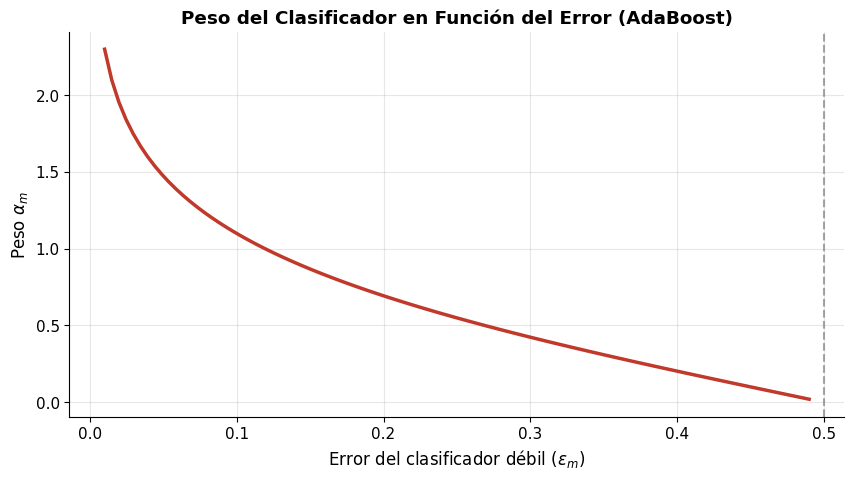

In [7]:
# Verificación simbólica de la fórmula de alpha en AdaBoost
print("="*80)
print("🔬 VERIFICACIÓN: FÓRMULA DE ALPHA EN ADABOOST")
print("="*80)

eps = Symbol('epsilon', positive=True)
alpha = sp.Rational(1, 2) * sp.log((1 - eps) / eps)

print("\nFórmula de alpha:")
display(sp.Eq(Symbol('alpha_m'), alpha))

print("\nComportamiento en casos límite:")
print("   - Si ε = 0.5 (aleatorio):")
alpha_05 = alpha.subs(eps, sp.Rational(1, 2))
print(f"     α = {alpha_05} → el clasificador NO aporta")

print("   - Si ε = 0.1 (muy bueno):")
alpha_01 = float(alpha.subs(eps, 0.1))
print(f"     α ≈ {alpha_01:.4f} → peso alto")

print("   - Si ε = 0.4 (regular):")
alpha_04 = float(alpha.subs(eps, 0.4))
print(f"     α ≈ {alpha_04:.4f} → peso bajo")

# Visualización
eps_vals = np.linspace(0.01, 0.49, 100)
alpha_vals = 0.5 * np.log((1 - eps_vals) / eps_vals)

plt.figure(figsize=(10, 5))
plt.plot(eps_vals, alpha_vals, linewidth=2.5, color='#C0392B')
plt.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7)
plt.xlabel('Error del clasificador débil ($\\epsilon_m$)', fontsize=12)
plt.ylabel('Peso $\\alpha_m$', fontsize=12)
plt.title('Peso del Clasificador en Función del Error (AdaBoost)', fontweight='bold')
plt.grid(alpha=0.3)
plt.show()

## 4.4 Gradient Boosting

**Friedman (2001).** Generaliza AdaBoost a cualquier función de pérdida diferenciable.

### Idea central

El boosting se formula como **descenso de gradiente en el espacio de funciones**. Cada modelo nuevo se ajusta a los **residuos negativos del gradiente** (pseudo-residuos).

### Algoritmo

**Inicialización:** $F_0(\mathbf{x}) = \arg\min_\gamma \sum_{i=1}^{n} L(y_i, \gamma)$

**Para** $m = 1, \ldots, M$:
1. Calcular los **pseudo-residuos** (gradiente negativo de la pérdida):
   $$\boxed{r_{im} = -\left[\frac{\partial L(y_i, F(\mathbf{x}_i))}{\partial F(\mathbf{x}_i)}\right]_{F = F_{m-1}}}$$
2. Entrenar un modelo débil $h_m(\mathbf{x})$ para predecir $r_{im}$
3. Calcular el paso óptimo:
   $$\gamma_m = \arg\min_\gamma \sum_{i=1}^{n} L(y_i, F_{m-1}(\mathbf{x}_i) + \gamma h_m(\mathbf{x}_i))$$
4. Actualizar el ensamble:
   $$\boxed{F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \nu \cdot \gamma_m h_m(\mathbf{x})}$$
   donde $\nu \in (0, 1]$ es la **tasa de aprendizaje (learning rate)**.

### Funciones de pérdida comunes

**Regresión (MSE):**
$$L(y, F) = \frac{1}{2}(y - F)^2 \quad \Rightarrow \quad r_{im} = y_i - F_{m-1}(\mathbf{x}_i)$$

**Clasificación binaria (Log-Loss):**
$$L(y, F) = \log(1 + e^{-y F}) \quad \Rightarrow \quad r_{im} = \frac{y_i}{1 + e^{y_i F_{m-1}(\mathbf{x}_i)}}$$

**Observación:** para MSE, los pseudo-residuos son simplemente los **residuos reales** $y_i - F_{m-1}(\mathbf{x}_i)$.

In [8]:
# Verificación: residuos de MSE son iguales a los pseudo-residuos
print("="*80)
print("🔬 VERIFICACIÓN: PSEUDO-RESIDUOS PARA MSE")
print("="*80)

y, F = symbols('y F', real=True)

# Pérdida cuadrática
L_mse = Rational(1, 2) * (y - F)**2
print("\nPérdida MSE:")
display(sp.Eq(Symbol('L(y, F)'), L_mse))

# Gradiente negativo (pseudo-residuo)
r = -diff(L_mse, F)
print("\nPseudo-residuo (gradiente negativo):")
display(sp.Eq(Symbol('r'), sp.simplify(r)))

print("\n✅ Para MSE, el pseudo-residuo es exactamente el residuo: y - F")

# Pérdida logística para clasificación binaria
print("\n" + "="*80)
print("Pérdida Log-Loss (clasificación binaria):")
print("="*80)
L_log = log(1 + exp(-y * F))
print("L(y, F) = log(1 + exp(-y·F))")

r_log = sp.simplify(-diff(L_log, F))
print("\nPseudo-residuo:")
display(sp.Eq(Symbol('r'), r_log))

print("\n💡 Este pseudo-residuo es la base de la 'corrección' que hace cada árbol")
print("   en Gradient Boosting para clasificación.")

🔬 VERIFICACIÓN: PSEUDO-RESIDUOS PARA MSE

Pérdida MSE:


                  2
          (-F + y) 
L(y, F) = ─────────
              2    


Pseudo-residuo (gradiente negativo):


r = -F + y


✅ Para MSE, el pseudo-residuo es exactamente el residuo: y - F

Pérdida Log-Loss (clasificación binaria):
L(y, F) = log(1 + exp(-y·F))

Pseudo-residuo:


       y    
r = ────────
     F⋅y    
    ℯ    + 1


💡 Este pseudo-residuo es la base de la 'corrección' que hace cada árbol
   en Gradient Boosting para clasificación.


## 4.5 XGBoost: Extreme Gradient Boosting

**Chen & Guestrin (2016).** Extensión de Gradient Boosting que añade:

1. **Regularización explícita** en la función objetivo
2. **Aproximación de segundo orden** (usa Hessiano)
3. **Algoritmos de construcción de árboles** (exact y approx)
4. **Paralelización** y optimizaciones de hardware
5. **Manejo nativo de valores faltantes**

### Función objetivo regularizada

$$\boxed{\mathcal{L}^{(m)} = \sum_{i=1}^{n} L(y_i, F_{m-1}(\mathbf{x}_i) + h_m(\mathbf{x}_i)) + \Omega(h_m)}$$

donde la regularización es:

$$\Omega(h) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^{T} w_j^2$$

con:
- $T$: número de hojas
- $w_j$: peso de la hoja $j$
- $\gamma$: penalización por número de hojas
- $\lambda$: penalización L2 sobre pesos de hojas

### Aproximación de segundo orden

Aplicando la expansión de Taylor de segundo orden a la pérdida:

$$\mathcal{L}^{(m)} \approx \sum_{i=1}^{n} \left[ L(y_i, F_{m-1}(\mathbf{x}_i)) + g_i h_m(\mathbf{x}_i) + \frac{1}{2} h_i h_m(\mathbf{x}_i)^2 \right] + \Omega(h_m)$$

donde:
- $g_i = \frac{\partial L(y_i, F_{m-1})}{\partial F_{m-1}}$: primer gradiente
- $h_i = \frac{\partial^2 L(y_i, F_{m-1})}{\partial F_{m-1}^2}$: segundo gradiente (Hessiano)

### Solución óptima de la hoja

Para una hoja con instancias $I_j$, el **peso óptimo** es:

$$\boxed{w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}}$$

Y la **pérdida óptima** resultante:

$$\boxed{\mathcal{L}^{(m)*} = -\frac{1}{2} \sum_{j=1}^{T} \frac{\left(\sum_{i \in I_j} g_i\right)^2}{\sum_{i \in I_j} h_i + \lambda} + \gamma T}$$

### Ganancia de la división

El **gain** de una división en XGBoost:

$$\boxed{\text{Gain} = \frac{1}{2} \left[ \frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda} \right] - \gamma}$$

donde $G_L, H_L, G_R, H_R$ son las sumas de gradientes y hessianos en las hojas izquierda y derecha.

**Interpretación:** la división se realiza solo si el Gain es positivo. El término $-\gamma$ penaliza divisiones innecesarias.

📊 COMPARACIÓN DE ALGORITMOS DE BOOSTING
        Algoritmo  Año Orden de aproximación Regularización Manejo de missing Paralelización  Velocidad               Uso típico
         AdaBoost 1997     1er (exponencial)   No explícita         No nativo             No      Media    Clasificación binaria
Gradient Boosting 2001       1er (gradiente)       Limitada          Limitado        Parcial      Media        Regresión general
          XGBoost 2016        2do (Hessiano)    L1 + L2 + γ            Nativo       Completa Muy rápida Competencias, producción


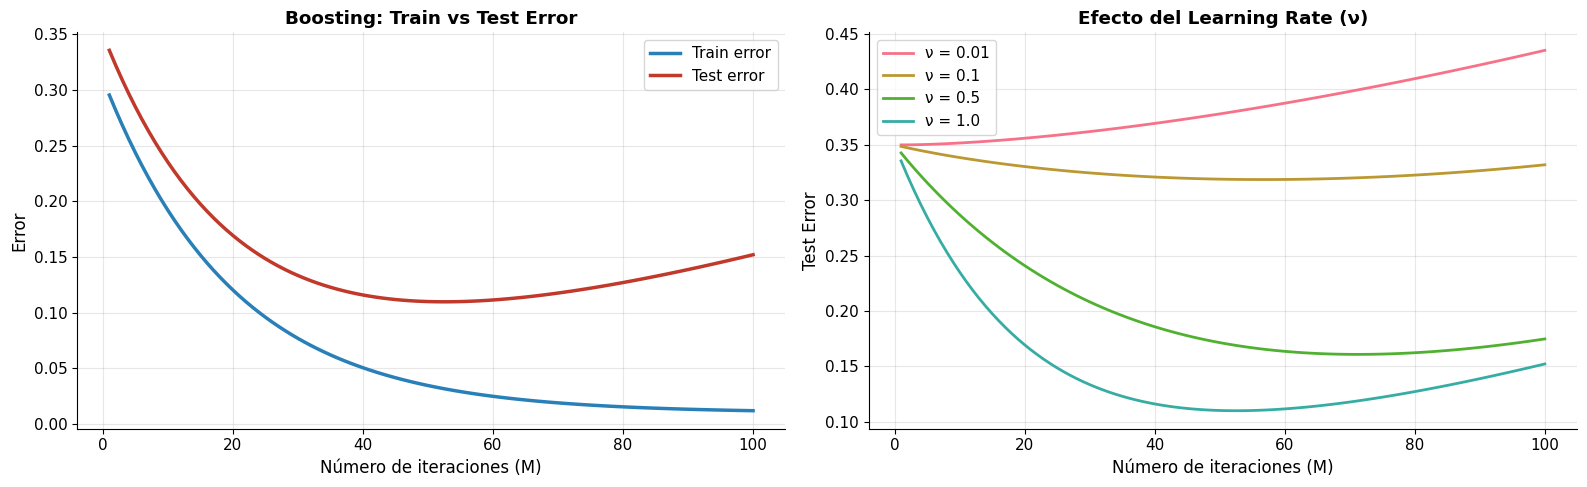


📊 Lecciones:
   - Train error baja monotónicamente con M
   - Test error baja y luego sube (sobreajuste con M grande)
   - Learning rate pequeño requiere más iteraciones pero generaliza mejor
   - Trade-off: ν pequeño + M grande vs ν grande + M pequeño


In [9]:
# Visualización conceptual: comparación de boosting algorithms
print("="*80)
print("📊 COMPARACIÓN DE ALGORITMOS DE BOOSTING")
print("="*80)

comparacion = pd.DataFrame({
    'Algoritmo': ['AdaBoost', 'Gradient Boosting', 'XGBoost'],
    'Año': [1997, 2001, 2016],
    'Orden de aproximación': ['1er (exponencial)', '1er (gradiente)', '2do (Hessiano)'],
    'Regularización': ['No explícita', 'Limitada', 'L1 + L2 + γ'],
    'Manejo de missing': ['No nativo', 'Limitado', 'Nativo'],
    'Paralelización': ['No', 'Parcial', 'Completa'],
    'Velocidad': ['Media', 'Media', 'Muy rápida'],
    'Uso típico': ['Clasificación binaria', 'Regresión general', 'Competencias, producción']
})

print(comparacion.to_string(index=False))

# Visualización del trade-off sesgo-varianza en boosting
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Error de entrenamiento vs número de iteraciones
M_iter = np.arange(1, 101)
train_err = 0.3 * np.exp(-0.05 * M_iter) + 0.01
test_err = 0.3 * np.exp(-0.05 * M_iter) + 0.05 + 0.0001 * M_iter**1.5

axes[0].plot(M_iter, train_err, linewidth=2.5, label='Train error', color='#2980B9')
axes[0].plot(M_iter, test_err, linewidth=2.5, label='Test error', color='#C0392B')
axes[0].set_xlabel('Número de iteraciones (M)', fontsize=12)
axes[0].set_ylabel('Error', fontsize=12)
axes[0].set_title('Boosting: Train vs Test Error', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Efecto del learning rate
for nu in [0.01, 0.1, 0.5, 1.0]:
    test_err_nu = 0.3 * np.exp(-0.05 * nu * M_iter) + 0.05 + 0.0001 * M_iter**1.5
    axes[1].plot(M_iter, test_err_nu, linewidth=2, label=f'ν = {nu}')

axes[1].set_xlabel('Número de iteraciones (M)', fontsize=12)
axes[1].set_ylabel('Test Error', fontsize=12)
axes[1].set_title('Efecto del Learning Rate (ν)', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📊 Lecciones:")
print("   - Train error baja monotónicamente con M")
print("   - Test error baja y luego sube (sobreajuste con M grande)")
print("   - Learning rate pequeño requiere más iteraciones pero generaliza mejor")
print("   - Trade-off: ν pequeño + M grande vs ν grande + M pequeño")

---
# Parte 5: Comparación y Guía Práctica

## 5.1 Tabla comparativa: Bagging vs Boosting

| Aspecto | Bagging | Boosting |
|---------|---------|----------|
| **Construcción** | Paralela (independiente) | Secuencial (dependiente) |
| **Objetivo** | Reducir **varianza** | Reducir **sesgo** |
| **Modelos base** | Fuertes (árboles profundos) | Débiles (árboles poco profundos) |
| **Pesos de muestras** | Iguales | Adaptativos (más peso a errores) |
| **Sobreajuste** | Raramente (mejora con M) | Sí (necesita regularización) |
| **Paralelización** | Trivial | Limitada (secuencial) |
| **Ejemplos** | Random Forest, Extra Trees | AdaBoost, GBM, XGBoost, LightGBM |

## 5.2 Cuándo usar cada método

**Random Forest (Bagging):**
- Datos con mucho **ruido**
- Necesitas **robustez** sin mucho tuning
- Problemas de **alta dimensionalidad**
- Baseline rápido para cualquier tarea

**Gradient Boosting (XGBoost, LightGBM):**
- Necesitas **máxima precisión**
- Datos **estructurados/tabulares**
- Tienes tiempo para tuning de hiperparámetros
- Competencias de ML y producción

**AdaBoost:**
- Problemas de **clasificación binaria** simples
- Base teórica sólida (margen)
- Menos usado en la práctica moderna (XGBoost lo supera)

## 5.3 Hiperparámetros clave

**Random Forest:**
- `n_estimators`: número de árboles (100-1000)
- `max_features`: features por split ($\sqrt{d}$ clasificación, $d/3$ regresión)
- `max_depth`: profundidad (controla complejidad)
- `min_samples_leaf`: mínimo en hojas

**Gradient Boosting / XGBoost:**
- `n_estimators`: número de iteraciones (100-10000)
- `learning_rate` ($\nu$): 0.01-0.3
- `max_depth`: 3-8 (árboles débiles)
- `subsample`: fracción de datos por iteración (0.5-1.0)
- `colsample_bytree`: fracción de features (0.5-1.0)
- `reg_alpha`, `reg_lambda`: regularización L1/L2
- `gamma`: mínimo Gain para dividir (XGBoost)

## 5.4 Guía de experimentación

1. **Baseline:** Random Forest con defaults
2. **Mejora:** XGBoost con defaults
3. **Tuning:** GridSearchCV o Bayesian Optimization
4. **Regularización:** añadir `subsample`, `colsample`, `reg_lambda`
5. **Interpretabilidad:** SHAP values, feature importances

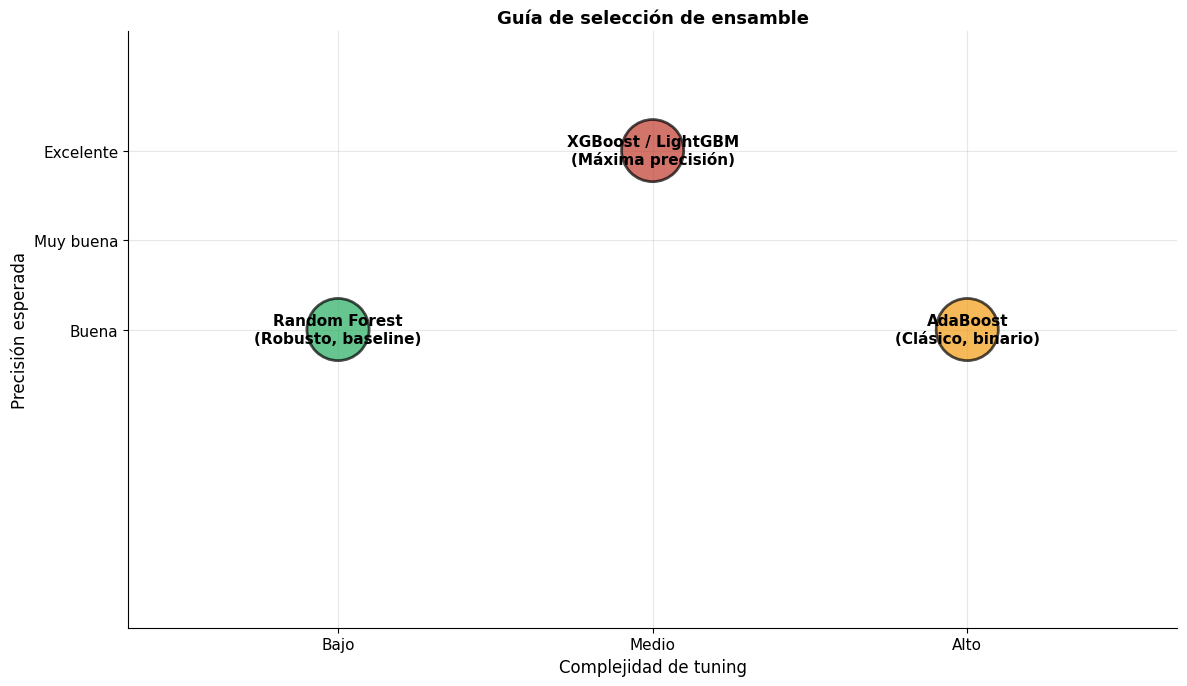

In [10]:
# Visualización resumen: cuándo usar cada método
fig, ax = plt.subplots(figsize=(12, 7))

# Crear un gráfico conceptual
x = [0.2, 0.5, 0.8]
y = [0.5, 0.8, 0.5]
labels = ['Random Forest\n(Robusto, baseline)',
          'XGBoost / LightGBM\n(Máxima precisión)',
          'AdaBoost\n(Clásico, binario)']
colors = ['#27AE60', '#C0392B', '#F39C12']

ax.scatter(x, y, s=2000, c=colors, edgecolor='black', linewidth=2, alpha=0.7, zorder=3)
for xi, yi, label in zip(x, y, labels):
    ax.annotate(label, (xi, yi), fontsize=11, ha='center', va='center', fontweight='bold', zorder=4)

ax.set_xlabel('Complejidad de tuning', fontsize=12)
ax.set_ylabel('Precisión esperada', fontsize=12)
ax.set_title('Guía de selección de ensamble', fontweight='bold', fontsize=13)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks([0.2, 0.5, 0.8])
ax.set_xticklabels(['Bajo', 'Medio', 'Alto'])
ax.set_yticks([0.5, 0.65, 0.8])
ax.set_yticklabels(['Buena', 'Muy buena', 'Excelente'])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
# Parte 6: Referencias Bibliográficas

## 6.1 Referencias fundacionales

1. **Breiman, L. (1996).** Bagging Predictors. *Machine Learning*, 24(2), 123-140. [Bagging original]
2. **Breiman, L. (2001).** Random Forests. *Machine Learning*, 45(1), 5-32. [Random Forest]
3. **Freund, Y., & Schapire, R. E. (1997).** A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting. *Journal of Computer and System Sciences*, 55(1), 119-139. [AdaBoost]
4. **Friedman, J. H. (2001).** Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189-1232. [Gradient Boosting]
5. **Friedman, J. H. (2002).** Stochastic Gradient Boosting. *Computational Statistics & Data Analysis*, 38(4), 367-378. [Stochastic GB]
6. **Chen, T., & Guestrin, C. (2016).** XGBoost: A Scalable Tree Boosting System. *KDD 2016*, 785-794. [XGBoost]

## 6.2 Referencias modernas

7. **Hastie, T., Tibshirani, R., & Friedman, J. (2009).** *The Elements of Statistical Learning* (2nd ed.). Springer. Capítulos 15-17. [ESL]
8. **Bishop, C. M. (2006).** *Pattern Recognition and Machine Learning*. Springer. Capítulo 14.
9. **Murphy, K. P. (2012).** *Machine Learning: A Probabilistic Perspective*. MIT Press. Capítulo 16.
10. **Zhou, Z.-H. (2012).** *Ensemble Methods: Foundations and Algorithms*. Chapman & Hall/CRC.

## 6.3 Extensiones modernas

11. **Ke, G., et al. (2017).** LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
12. **Prokhorenkova, L., et al. (2018).** CatBoost: Unbiased Boosting with Categorical Features. *NeurIPS 2018*.
13. **Lundberg, S. M., & Lee, S. I. (2017).** A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*. [SHAP]
14. **Wolpert, D. H. (1992).** Stacked Generalization. *Neural Networks*, 5(2), 241-259. [Stacking]

## 6.4 Referencias pedagógicas

15. **Raschka, S., & Mirjalili, V. (2019).** *Python Machine Learning* (3rd ed.). Packt. Capítulo 7.
16. **Géron, A. (2022).** *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly. Capítulo 7.
17. **Scikit-learn Developers (2024).** *Ensemble methods*. https://scikit-learn.org/stable/modules/ensemble.html

---
# Parte 7: Resumen y Ejercicios

## 7.1 Resumen de Ecuaciones Clave

| Concepto | Ecuación |
|----------|----------|
| **Error del ensamble** | $\mathbb{E}[\epsilon_{\text{ens}}^2] = \rho \sigma^2 + \frac{1-\rho}{M} \sigma^2$ |
| **Bagging (predicción)** | $\hat{f}_{\text{bag}} = \frac{1}{M} \sum_m \hat{f}_m$ |
| **Bootstrap únicos** | $P(\text{única}) = 1 - e^{-1} \approx 0.632$ |
| **Boosting (predicción)** | $F_M(\mathbf{x}) = \sum_m \alpha_m h_m(\mathbf{x})$ |
| **AdaBoost (peso)** | $\alpha_m = \frac{1}{2} \ln\left(\frac{1-\epsilon_m}{\epsilon_m}\right)$ |
| **AdaBoost (re-weight)** | $w_i^{(m+1)} \propto w_i^{(m)} e^{-\alpha_m y_i h_m(\mathbf{x}_i)}$ |
| **GB (pseudo-residuo)** | $r_{im} = -\frac{\partial L(y_i, F)}{\partial F}\bigg|_{F=F_{m-1}}$ |
| **GB (actualización)** | $F_m = F_{m-1} + \nu \gamma_m h_m$ |
| **XGBoost (objetivo)** | $\mathcal{L} + \gamma T + \frac{1}{2} \lambda \sum_j w_j^2$ |
| **XGBoost (hoja óptima)** | $w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}$ |
| **XGBoost (ganancia)** | $\frac{1}{2}\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma$ |

## 7.2 Ejercicios Teóricos

### Ejercicio 1: Descomposición del error del ensamble
Demuestra que $\mathbb{E}[\epsilon_{\text{ens}}^2] = \rho \sigma^2 + \frac{1-\rho}{M} \sigma^2$ partiendo de la definición de correlación entre errores.

### Ejercicio 2: AdaBoost en un ejemplo 1D
En un problema con 4 muestras, un clasificador débil comete 1 error. Calcula $\alpha_1$ y los nuevos pesos $w_i^{(2)}$.

### Ejercicio 3: Gradient Boosting para regresión
Demuestra que para MSE, el pseudo-residuo es igual al residuo: $r_{im} = y_i - F_{m-1}(\mathbf{x}_i)$.

### Ejercicio 4: XGBoost con regularización
Dado un nodo con $G_L = 3, H_L = 2, G_R = 5, H_R = 3, \lambda = 1, \gamma = 0.5$, calcula el Gain de la división. ¿Vale la pena dividir?

### Ejercicio 5: Comparación conceptual
Explica en términos de sesgo-varianza por qué Random Forest no suele sobreajustar con M grande, mientras que Gradient Boosting sí.

In [11]:
# SOLUCIÓN Ejercicio 2: AdaBoost en un ejemplo 1D
print("="*80)
print("🔬 SOLUCIÓN Ejercicio 2: AdaBoost con 4 muestras")
print("="*80)

n = 4
w_inicial = np.ones(n) / n
error_h1 = 1  # 1 error de 4
epsilon_1 = error_h1 / n

print(f"\nPesos iniciales: {w_inicial}")
print(f"Error del clasificador: ε₁ = {error_h1}/{n} = {epsilon_1}")

# Calcular alpha
alpha_1 = 0.5 * np.log((1 - epsilon_1) / epsilon_1)
print(f"\nalpha_1 = 0.5 · ln((1 - {epsilon_1}) / {epsilon_1}) = {alpha_1:.4f}")

# Actualizar pesos (muestra mal clasificada se multiplica por e^alpha)
y_true = np.array([1, 1, -1, -1])
h_1 = np.array([1, -1, -1, -1])  # Error en la muestra 1 (índice 1)

w_nuevo = w_inicial * np.exp(-alpha_1 * y_true * h_1)
w_normalizado = w_nuevo / w_nuevo.sum()

print(f"\nPesos sin normalizar: {w_nuevo.round(4)}")
print(f"Pesos normalizados:   {w_normalizado.round(4)}")
print(f"\n💡 Observación:")
print(f"   - La muestra MAL clasificada (índice 1) tiene ahora peso {w_normalizado[1]:.4f}")
print(f"   - Las muestras bien clasificadas tienen peso {w_normalizado[0]:.4f}")
print(f"   - El clasificador débil se enfocará más en la muestra difícil")

🔬 SOLUCIÓN Ejercicio 2: AdaBoost con 4 muestras

Pesos iniciales: [0.25 0.25 0.25 0.25]
Error del clasificador: ε₁ = 1/4 = 0.25

alpha_1 = 0.5 · ln((1 - 0.25) / 0.25) = 0.5493

Pesos sin normalizar: [0.1443 0.433  0.1443 0.1443]
Pesos normalizados:   [0.1667 0.5    0.1667 0.1667]

💡 Observación:
   - La muestra MAL clasificada (índice 1) tiene ahora peso 0.5000
   - Las muestras bien clasificadas tienen peso 0.1667
   - El clasificador débil se enfocará más en la muestra difícil


In [12]:
# SOLUCIÓN Ejercicio 4: XGBoost Gain
print("="*80)
print("🔬 SOLUCIÓN Ejercicio 4: Gain de división en XGBoost")
print("="*80)

G_L, H_L = 3, 2
G_R, H_R = 5, 3
lam = 1.0
gamma = 0.5

# Calcular términos de la fórmula del Gain
term_L = G_L**2 / (H_L + lam)
term_R = G_R**2 / (H_R + lam)
term_total = (G_L + G_R)**2 / (H_L + H_R + lam)

gain = 0.5 * (term_L + term_R - term_total) - gamma

print(f"\nDatos:")
print(f"   Hoja izquierda: G_L={G_L}, H_L={H_L}")
print(f"   Hoja derecha:   G_R={G_R}, H_R={H_R}")
print(f"   λ = {lam}, γ = {gamma}")

print(f"\nCálculo:")
print(f"   G_L²/(H_L+λ) = {G_L}²/({H_L}+{lam}) = {term_L:.4f}")
print(f"   G_R²/(H_R+λ) = {G_R}²/({H_R}+{lam}) = {term_R:.4f}")
print(f"   (G_L+G_R)²/(H_L+H_R+λ) = ({G_L}+{G_R})²/({H_L}+{H_R}+{lam}) = {term_total:.4f}")

print(f"\nGain = 0.5 · ({term_L:.4f} + {term_R:.4f} - {term_total:.4f}) - {gamma}")
print(f"Gain = 0.5 · {term_L + term_R - term_total:.4f} - {gamma}")
print(f"Gain = {gain:.4f}")

if gain > 0:
    print(f"\n✅ Gain > 0 → CONVIENE dividir")
else:
    print(f"\n❌ Gain ≤ 0 → NO conviene dividir")

🔬 SOLUCIÓN Ejercicio 4: Gain de división en XGBoost

Datos:
   Hoja izquierda: G_L=3, H_L=2
   Hoja derecha:   G_R=5, H_R=3
   λ = 1.0, γ = 0.5

Cálculo:
   G_L²/(H_L+λ) = 3²/(2+1.0) = 3.0000
   G_R²/(H_R+λ) = 5²/(3+1.0) = 6.2500
   (G_L+G_R)²/(H_L+H_R+λ) = (3+5)²/(2+3+1.0) = 10.6667

Gain = 0.5 · (3.0000 + 6.2500 - 10.6667) - 0.5
Gain = 0.5 · -1.4167 - 0.5
Gain = -1.2083

❌ Gain ≤ 0 → NO conviene dividir


## 7.3 Conclusiones Finales

### Ideas clave

1. **Los ensambles combinan modelos débiles** para crear un modelo fuerte con menor error
2. **Bagging y Random Forest reducen varianza** mediante paralelización y decorrelación
3. **Boosting reduce sesgo** mediante corrección secuencial de errores
4. **Random Forest añade aleatoriedad** en features para reducir correlación entre árboles
5. **AdaBoost ajusta pesos** de muestras basándose en el error
6. **Gradient Boosting** generaliza AdaBoost con gradiente de cualquier pérdida
7. **XGBoost** añade regularización explícita, segundo orden y paralelización
8. **La elección del ensamble depende** del problema, datos y recursos disponibles

### Mensaje pedagógico

Los métodos de ensamble son el **estado del arte** en datos tabulares. Dominar:
- La **diferencia conceptual** entre bagging y boosting
- Los **hiperparámetros clave** de cada método
- Las **guías prácticas** para elegir el método correcto

te permite construir soluciones robustas para problemas reales.

En la práctica aplicaremos estos conceptos a:
1. **Dataset sintético** para comparar los métodos
2. **Dataset académico** (Remontada) para comparar con SVM y árboles simples